**Intalling DeepFace**

In [ ]:
!pip install deepface -q

In [2]:
from sklearn.datasets import fetch_lfw_pairs
import numpy as np
import time
from deepface import DeepFace
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

26-10-24 07:35:57 - Directory /root/.deepface has been created
26-10-24 07:35:57 - Directory /root/.deepface/weights has been created


In [7]:
print("Loading LFW dataset...")
lfw_data = fetch_lfw_pairs(subset='test', color=True, resize=1.0)
image_pairs = lfw_data.pairs      # shape: (N, 2, H, W, 3)
target_labels = lfw_data.target    # 1 if same, 0 if diff

print("Total pairs we got:", len(image_pairs))

# Using 100 pairs for now, 50 for same and 50 for different
same_idx = np.where(target_labels == 1)[0][:50]
diff_idx = np.where(target_labels == 0)[0][:50]
keep_idx = np.concatenate([same_idx, diff_idx])

image_pairs = image_pairs[keep_idx]
target_labels = target_labels[keep_idx]

print("Trimming down to:", len(image_pairs), "pairs")
print("Stats -> same:", sum(target_labels), "| diff:", len(target_labels) - sum(target_labels))

Loading LFW dataset...
Total pairs we got: 1000
Trimming down to: 100 pairs
Stats -> same: 50 | diff: 50


**Getting similarity for each pair and time it**

In [8]:
similarity_scores = []
loop_start_time = time.time()

for idx in range(len(image_pairs)):
    # LFW images are floats between 0 and 1, need to scale them up to 255
    img_one = (image_pairs[idx][0] * 255).astype(np.uint8)
    img_two = (image_pairs[idx][1] * 255).astype(np.uint8)

    try:
        res = DeepFace.verify(img_one, img_two, model_name="ArcFace", enforce_detection=False)
        similarity_scores.append(res["distance"])
    except Exception as err:
        similarity_scores.append(None)
        print(f"Oops, pair {idx} messed up:", err)

total_time = time.time() - loop_start_time

# filtering out Nones just in case something failed
clean_similarities = []
for s in similarity_scores:
    if s is not None:
        clean_similarities.append(s)

similarities_arr = np.array(clean_similarities)

print(f"Done! Took {round(total_time, 1)} seconds for {len(similarities_arr)} pairs.")
print("Average time per loop:", round(total_time / len(image_pairs), 3), "s")

Done! Took 85.3 seconds for 100 pairs.
Average time per loop: 0.853 s


**Testing at two different thresholds, one a stricker and other one a little looser to show the trade-off**

In [9]:
valid_labels = target_labels[:len(similarities_arr)]
# DeepFace default for ArcFace is around 0.68
thresholds_to_try = [0.60, 0.68]

for thres in thresholds_to_try:
    preds = []
    for val in similarities_arr:
        if val < thres:
            preds.append(1)
        else:
            preds.append(0)
    preds = np.array(preds)

    acc = np.mean(preds == valid_labels)

    # checking error types
    false_pos = 0
    false_neg = 0
    for p, t in zip(preds, valid_labels):
        if p == 1 and t == 0:
            false_pos += 1
        elif p == 0 and t == 1:
            false_neg += 1

    print(f"Threshold: {thres} -> Accuracy: {round(acc, 3)} | False accepts: {false_pos} | False rejects: {false_neg}")

Threshold: 0.6 -> Accuracy: 0.9 | False accepts: 0 | False rejects: 10
Threshold: 0.68 -> Accuracy: 0.91 | False accepts: 1 | False rejects: 8


**Calculating the Accuracy and plotting a histogram to see guiune vs fake**

Final AUC score: 0.957
Saved histogram plot as similarity_histogram.png


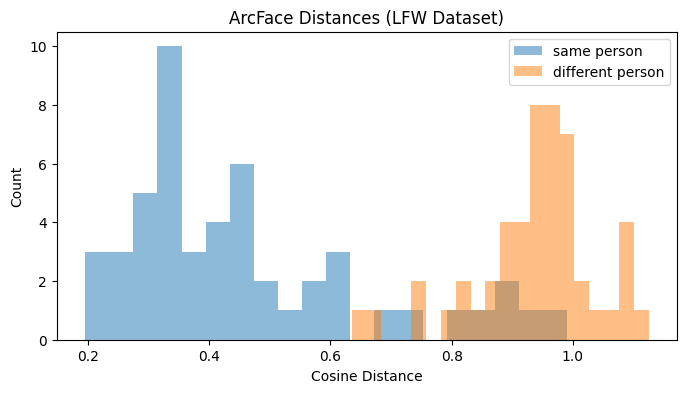

In [10]:
confidence_scores = -similarities_arr
final_auc = roc_auc_score(valid_labels, confidence_scores)
print("Final AUC score:", round(final_auc, 3))

# Plotting results
plt.figure(figsize=(8,4))
plt.hist(similarities_arr[valid_labels == 1], bins=20, alpha=0.5, label="same person")
plt.hist(similarities_arr[valid_labels == 0], bins=20, alpha=0.5, label="different person")
plt.xlabel("Cosine Distance")
plt.ylabel("Count")
plt.title("ArcFace Distances (LFW Dataset)")
plt.legend()
plt.savefig("similarity_histogram.png", dpi=150, bbox_inches="tight")
print("Saved histogram plot as similarity_histogram.png")
plt.show()